# Telco Churn: Exploratory Data Analysis

**Purpose:** Identify which customer and service attributes are most strongly associated with churn. Every analysis shows segment *size* alongside churn *rate* — a high rate in a tiny group is less actionable than a moderate rate in a large group.

**Denominator note:** Churn rate = churned customers ÷ all customers in that segment. All percentages are proportions of the segment, not of the total base, unless stated otherwise.

**Causation caveat:** Associations identified here do not prove causation. This dataset does not capture why individual customers left.

## 1. Load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

# Walk up from the kernel's working directory until we find the project root
# (identified by data/clean/telco_clean.csv existing there). This handles the
# notebooks/notebooks/ quirk observed in the previous session.
FILE_NAME = "telco_clean.csv"

project_root = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data" / "clean" / FILE_NAME).exists()
)

clean_path = project_root / "data" / "clean" / FILE_NAME
images_dir = project_root / "images"
images_dir.mkdir(exist_ok=True)

df = pd.read_csv(clean_path)

# Add a numeric churn flag (1 = churned, 0 = retained) for arithmetic.
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Loaded from:", clean_path.resolve())
print("Shape:", df.shape)
print("Overall churn rate:", f"{df['ChurnFlag'].mean():.1%}")
print("Columns:", df.columns.tolist())

Loaded from: D:\telco-churn-analytics\data\clean\telco_clean.csv
Shape: (7043, 23)
Overall churn rate: 26.5%
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'SeniorCitizenLabel', 'ChurnFlag']


## 2. Churn by contract type

Contract type is typically the strongest single predictor of churn in subscription businesses. Month-to-month customers face no switching cost, so they can leave at any time. One-year and two-year contracts create friction that keeps customers even if satisfaction drops.

The table below shows: how many customers are in each contract group, how many churned, and the churn rate. We always show counts alongside rates — a 50% churn rate on 10 customers is very different from 50% on 2,000.

In [2]:
# --- Churn by contract type ---
contract_summary = (
    df.groupby("Contract")["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .sort_values("churn_rate", ascending=False)
)
contract_summary["churn_rate_pct"] = contract_summary["churn_rate"].map("{:.1%}".format)

print("=== Churn by Contract Type ===")
print(contract_summary[["customers", "churned", "churn_rate_pct"]].to_string())
print()
print("Interpretation: Month-to-month customers churn at a far higher rate than")
print("annual or two-year contract holders. The month-to-month group is also the")
print("largest, so it drives the most absolute churn volume.")

=== Churn by Contract Type ===
                customers  churned churn_rate_pct
Contract                                         
Month-to-month       3875     1655          42.7%
One year             1473      166          11.3%
Two year             1695       48           2.8%

Interpretation: Month-to-month customers churn at a far higher rate than
annual or two-year contract holders. The month-to-month group is also the
largest, so it drives the most absolute churn volume.


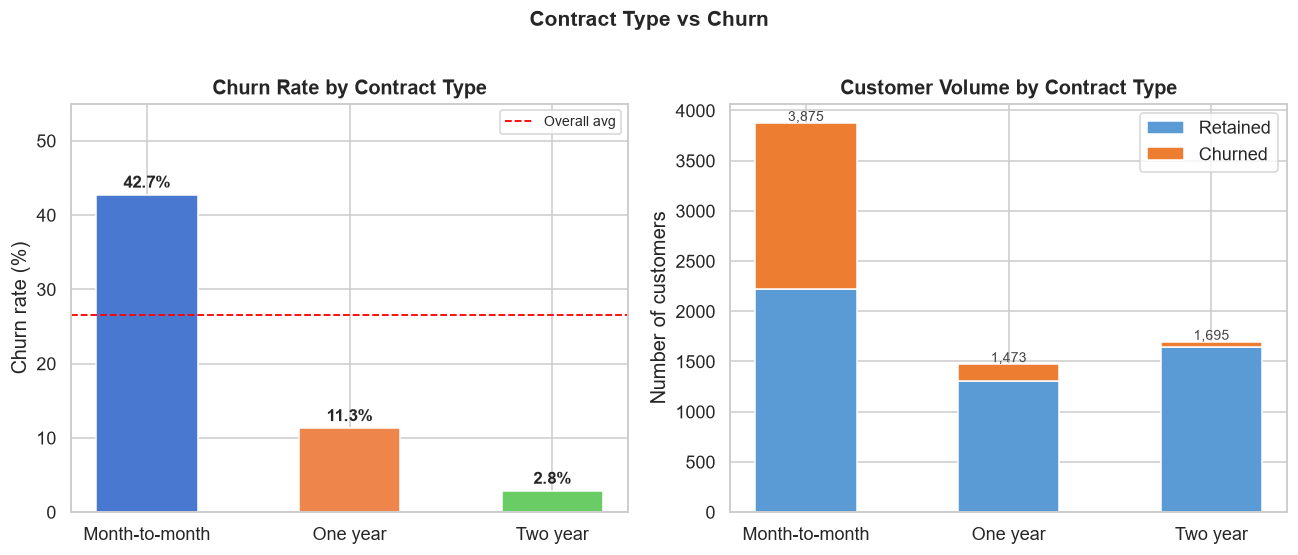

Saved: images/02_01_churn_by_contract.png


In [3]:
# --- Visualise contract churn: dual view (rate + volume) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

contract_order = ["Month-to-month", "One year", "Two year"]
plot_data = contract_summary.reindex(contract_order)

# Left: churn rate per contract
bars = axes[0].bar(
    plot_data.index,
    plot_data["churn_rate"] * 100,
    color=sns.color_palette("muted", 3),
    edgecolor="white",
    width=0.5,
)
for bar, val in zip(bars, plot_data["churn_rate"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1%}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )
axes[0].set_title("Churn Rate by Contract Type", fontweight="bold")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 55)
axes[0].axhline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", linewidth=1.2, label="Overall avg")
axes[0].legend(fontsize=9)

# Right: stacked bar showing churned vs retained volume
retained = plot_data["customers"] - plot_data["churned"]
axes[1].bar(plot_data.index, retained, label="Retained", color="#5b9bd5", edgecolor="white", width=0.5)
axes[1].bar(plot_data.index, plot_data["churned"], bottom=retained, label="Churned", color="#ed7d31", edgecolor="white", width=0.5)
for i, (ret, churn) in enumerate(zip(retained, plot_data["churned"])):
    axes[1].text(i, ret + churn + 20, f"{ret + churn:,}", ha="center", fontsize=9, color="#444")
axes[1].set_title("Customer Volume by Contract Type", fontweight="bold")
axes[1].set_ylabel("Number of customers")
axes[1].legend()

fig.suptitle("Contract Type vs Churn", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "02_01_churn_by_contract.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_01_churn_by_contract.png")

## 3. Churn by tenure

Tenure (months as a customer) is the other key dimension. New customers are most vulnerable — they haven't yet built habit or realised the product's value. The longer a customer stays, the lower their observed churn rate tends to be.

We bin tenure into 1-year buckets (0–12, 13–24, …) to compare cohorts. We also plot the raw distribution split by churn label.

In [4]:
# --- Churn by tenure bucket ---
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ["0–12 mo", "13–24 mo", "25–36 mo", "37–48 mo", "49–60 mo", "61–72 mo"]
df["TenureBucket"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

tenure_summary = (
    df.groupby("TenureBucket", observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
)
tenure_summary["churn_rate_pct"] = tenure_summary["churn_rate"].map("{:.1%}".format)

print("=== Churn by Tenure Bucket ===")
print(tenure_summary[["customers", "churned", "churn_rate_pct"]].to_string())
print()
print("Interpretation: Customers in their first year churn at the highest rate.")
print("Those who pass the 24-month mark have substantially lower churn rates.")

=== Churn by Tenure Bucket ===
              customers  churned churn_rate_pct
TenureBucket                                   
0–12 mo            2186     1037          47.4%
13–24 mo           1024      294          28.7%
25–36 mo            832      180          21.6%
37–48 mo            762      145          19.0%
49–60 mo            832      120          14.4%
61–72 mo           1407       93           6.6%

Interpretation: Customers in their first year churn at the highest rate.
Those who pass the 24-month mark have substantially lower churn rates.


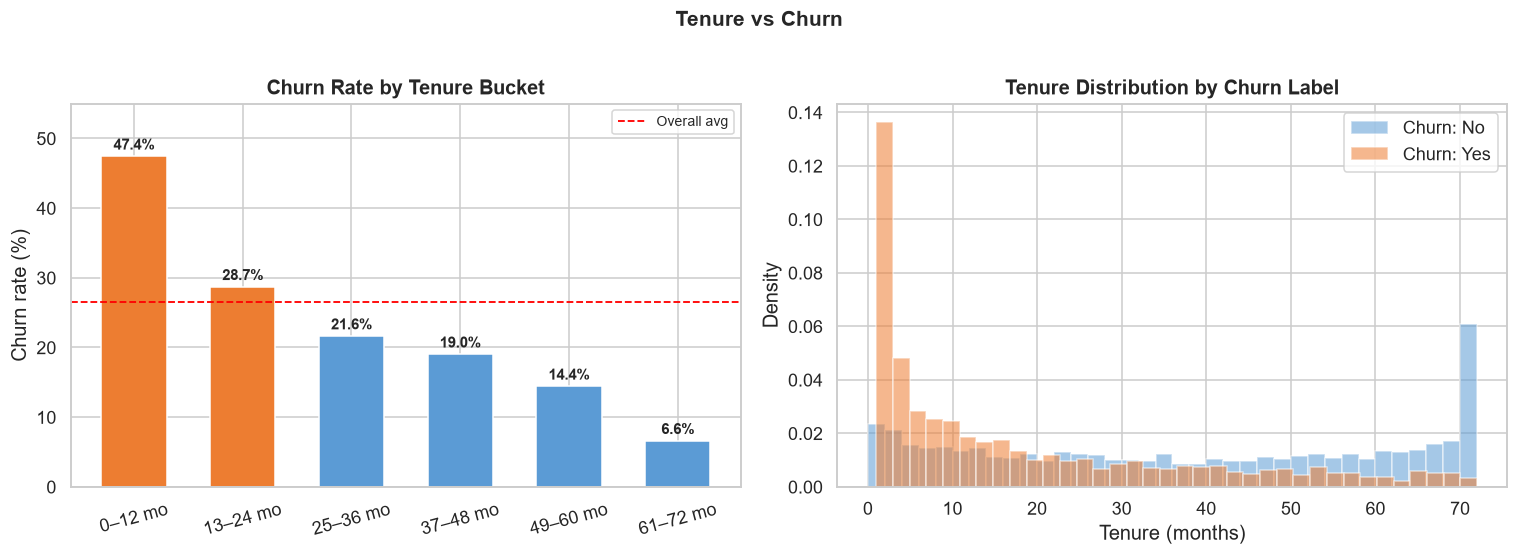

Saved: images/02_02_churn_by_tenure.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: churn rate by tenure bucket (bar)
colors = ["#ed7d31" if r > df["ChurnFlag"].mean() else "#5b9bd5"
          for r in tenure_summary["churn_rate"]]
bars = axes[0].bar(
    tenure_summary.index,
    tenure_summary["churn_rate"] * 100,
    color=colors,
    edgecolor="white",
    width=0.6,
)
for bar, val in zip(bars, tenure_summary["churn_rate"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1%}",
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )
axes[0].axhline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", linewidth=1.2, label="Overall avg")
axes[0].set_title("Churn Rate by Tenure Bucket", fontweight="bold")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 55)
axes[0].legend(fontsize=9)
axes[0].tick_params(axis="x", rotation=15)

# Right: tenure distribution split by churn label (KDE / histogram)
for label, grp in df.groupby("Churn"):
    axes[1].hist(
        grp["tenure"],
        bins=36,
        alpha=0.55,
        label=f"Churn: {label}",
        color="#ed7d31" if label == "Yes" else "#5b9bd5",
        edgecolor="white",
        density=True,
    )
axes[1].set_title("Tenure Distribution by Churn Label", fontweight="bold")
axes[1].set_xlabel("Tenure (months)")
axes[1].set_ylabel("Density")
axes[1].legend()

fig.suptitle("Tenure vs Churn", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "02_02_churn_by_tenure.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_02_churn_by_tenure.png")

## 4. Churn by payment method

Payment method can signal engagement and financial stability. Automatic payment methods (bank transfer, credit card) are associated with lower churn in many subscription contexts — customers who set up automatic payments have committed to the relationship more deliberately. Electronic check is a manual method and may be used by customers with less stable arrangements.

=== Churn by Payment Method ===
                           customers  churned churn_rate_pct
PaymentMethod                                               
Electronic check                2365     1071          45.3%
Mailed check                    1612      308          19.1%
Bank transfer (automatic)       1544      258          16.7%
Credit card (automatic)         1522      232          15.2%


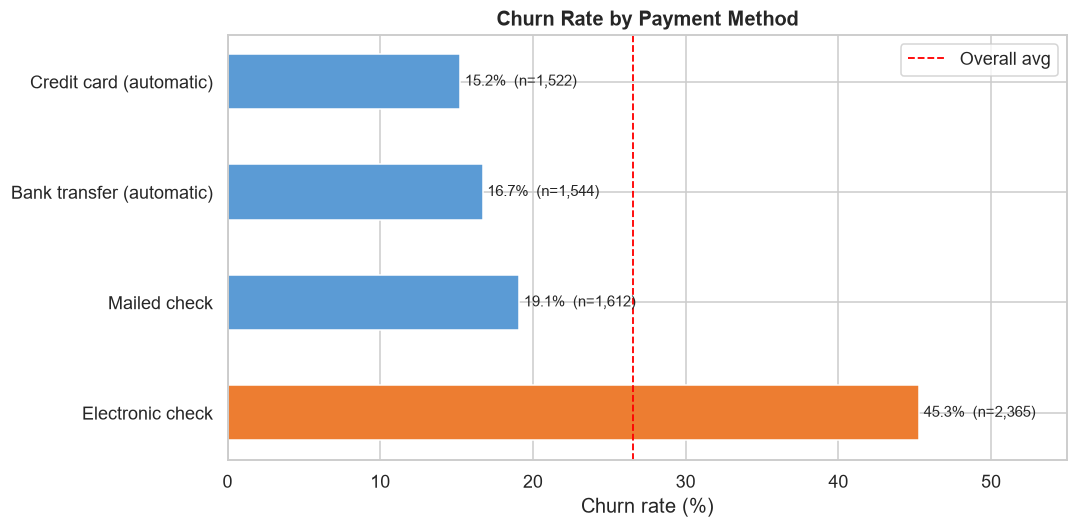

Saved: images/02_03_churn_by_payment.png


In [6]:
payment_summary = (
    df.groupby("PaymentMethod")["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .sort_values("churn_rate", ascending=False)
)
payment_summary["churn_rate_pct"] = payment_summary["churn_rate"].map("{:.1%}".format)

print("=== Churn by Payment Method ===")
print(payment_summary[["customers", "churned", "churn_rate_pct"]].to_string())

fig, ax = plt.subplots(figsize=(10, 5))
palette = ["#ed7d31" if r > df["ChurnFlag"].mean() else "#5b9bd5"
           for r in payment_summary["churn_rate"]]
bars = ax.barh(
    payment_summary.index,
    payment_summary["churn_rate"] * 100,
    color=palette,
    edgecolor="white",
    height=0.5,
)
for bar, val, cnt in zip(bars, payment_summary["churn_rate"], payment_summary["customers"]):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1%}  (n={cnt:,})",
        va="center", fontsize=10,
    )
ax.axvline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", linewidth=1.2, label="Overall avg")
ax.set_title("Churn Rate by Payment Method", fontweight="bold")
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, 55)
ax.legend()
plt.tight_layout()
plt.savefig(images_dir / "02_03_churn_by_payment.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_03_churn_by_payment.png")

## 5. Churn by internet service type

Internet service type is worth examining because Fiber Optic customers pay more and may have higher expectations. If Fiber customers churn more, it could indicate pricing sensitivity, service quality, or competition at the high end of the market.

=== Churn by Internet Service Type ===
                 customers  churned churn_rate_pct
InternetService                                   
Fiber optic           3096     1297          41.9%
DSL                   2421      459          19.0%
No                    1526      113           7.4%


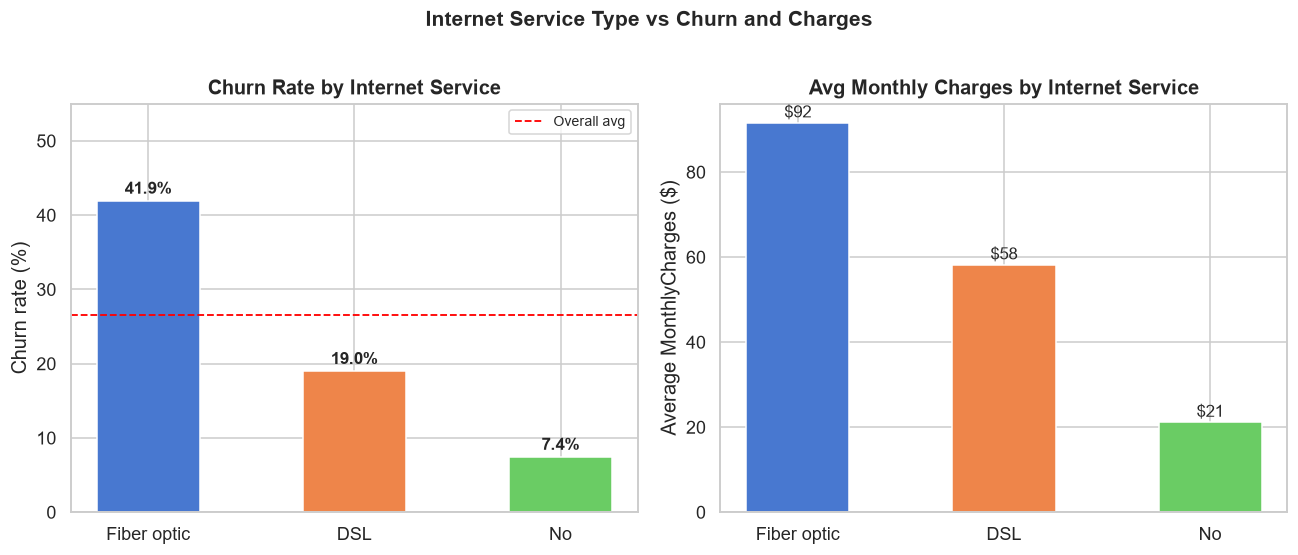

Saved: images/02_04_churn_by_internet.png


In [7]:
internet_summary = (
    df.groupby("InternetService")["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .sort_values("churn_rate", ascending=False)
)
internet_summary["churn_rate_pct"] = internet_summary["churn_rate"].map("{:.1%}".format)

print("=== Churn by Internet Service Type ===")
print(internet_summary[["customers", "churned", "churn_rate_pct"]].to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

palette = sns.color_palette("muted", 3)
bars = axes[0].bar(
    internet_summary.index,
    internet_summary["churn_rate"] * 100,
    color=palette,
    edgecolor="white",
    width=0.5,
)
for bar, val in zip(bars, internet_summary["churn_rate"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1%}",
        ha="center", va="bottom", fontsize=11, fontweight="bold",
    )
axes[0].axhline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", linewidth=1.2, label="Overall avg")
axes[0].set_title("Churn Rate by Internet Service", fontweight="bold")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 55)
axes[0].legend(fontsize=9)

# Average monthly charges per internet service group
avg_charges = df.groupby("InternetService")["MonthlyCharges"].mean().reindex(internet_summary.index)
axes[1].bar(
    avg_charges.index,
    avg_charges.values,
    color=palette,
    edgecolor="white",
    width=0.5,
)
for i, (idx, val) in enumerate(avg_charges.items()):
    axes[1].text(i, val + 0.5, f"${val:.0f}", ha="center", va="bottom", fontsize=11)
axes[1].set_title("Avg Monthly Charges by Internet Service", fontweight="bold")
axes[1].set_ylabel("Average MonthlyCharges ($)")

fig.suptitle("Internet Service Type vs Churn and Charges", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "02_04_churn_by_internet.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_04_churn_by_internet.png")

## 6. Churn by senior citizen status

Senior citizens (SeniorCitizen = 1) make up about 16% of the base. If they churn at a different rate, the company should consider whether its digital-first products and billing methods serve them well.

In [8]:
senior_summary = (
    df.groupby("SeniorCitizenLabel")["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(
        churn_rate=lambda x: x["churned"] / x["customers"],
        pct_of_base=lambda x: x["customers"] / len(df),
    )
)
senior_summary["churn_rate_pct"] = senior_summary["churn_rate"].map("{:.1%}".format)
senior_summary["pct_of_base_pct"] = senior_summary["pct_of_base"].map("{:.1%}".format)

print("=== Churn by Senior Citizen Status ===")
print(senior_summary[["customers", "churned", "churn_rate_pct", "pct_of_base_pct"]].to_string())

=== Churn by Senior Citizen Status ===
                    customers  churned churn_rate_pct pct_of_base_pct
SeniorCitizenLabel                                                   
No                       5901     1393          23.6%           83.8%
Yes                      1142      476          41.7%           16.2%


## 7. Churn by other categorical features

We now sweep through the remaining categorical columns — partner, dependents, paperless billing, phone service, and key add-ons — using a reusable function. Each result shows counts and rates.

In [9]:
def churn_summary(col: str) -> pd.DataFrame:
    """Return customer count, churned count, and churn rate for each value of col."""
    return (
        df.groupby(col)["ChurnFlag"]
        .agg(customers="count", churned="sum")
        .assign(churn_rate=lambda x: x["churned"] / x["customers"])
        .sort_values("churn_rate", ascending=False)
    )

cat_cols = [
    "Partner", "Dependents", "PaperlessBilling",
    "PhoneService", "OnlineSecurity", "TechSupport",
    "OnlineBackup", "DeviceProtection",
]

for col in cat_cols:
    s = churn_summary(col)
    s["churn_rate_pct"] = s["churn_rate"].map("{:.1%}".format)
    print(f"--- {col} ---")
    print(s[["customers", "churned", "churn_rate_pct"]].to_string())
    print()

--- Partner ---
         customers  churned churn_rate_pct
Partner                                   
No            3641     1200          33.0%
Yes           3402      669          19.7%

--- Dependents ---
            customers  churned churn_rate_pct
Dependents                                   
No               4933     1543          31.3%
Yes              2110      326          15.5%

--- PaperlessBilling ---
                  customers  churned churn_rate_pct
PaperlessBilling                                   
Yes                    4171     1400          33.6%
No                     2872      469          16.3%

--- PhoneService ---
              customers  churned churn_rate_pct
PhoneService                                   
Yes                6361     1699          26.7%
No                  682      170          24.9%

--- OnlineSecurity ---
                     customers  churned churn_rate_pct
OnlineSecurity                                        
No                        

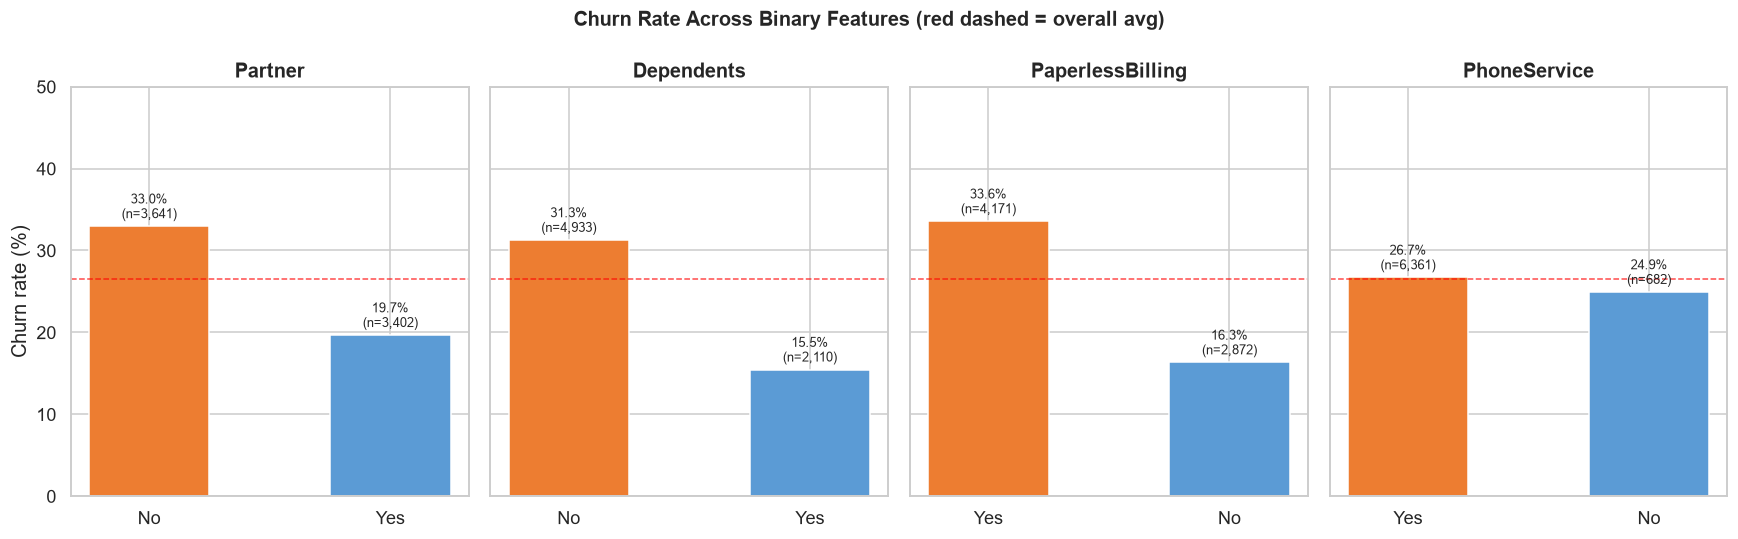

Saved: images/02_05_churn_binary_features.png


In [10]:
# --- Visualise: grid of churn rates across binary/ternary categorical features ---
# Focus on features with a clear Yes/No contrast (excluding 'No internet/phone service')

binary_cols = ["Partner", "Dependents", "PaperlessBilling", "PhoneService"]

fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
overall_rate = df["ChurnFlag"].mean() * 100

for ax, col in zip(axes, binary_cols):
    s = churn_summary(col)
    vals = s["churn_rate"] * 100
    colors = ["#ed7d31" if v > overall_rate else "#5b9bd5" for v in vals]
    bars = ax.bar(s.index, vals, color=colors, edgecolor="white", width=0.5)
    for bar, v, cnt in zip(bars, vals, s["customers"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{v:.1f}%\n(n={cnt:,})",
            ha="center", va="bottom", fontsize=8.5,
        )
    ax.axhline(overall_rate, color="red", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_title(col, fontweight="bold")
    ax.set_ylim(0, 50)

axes[0].set_ylabel("Churn rate (%)")
fig.suptitle("Churn Rate Across Binary Features (red dashed = overall avg)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(images_dir / "02_05_churn_binary_features.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_05_churn_binary_features.png")

## 8. MonthlyCharges distribution by churn label

Churned customers tend to have higher monthly charges. This could mean they were on expensive plans with insufficient perceived value, or it could be a confounder — Fiber Optic users both pay more and churn more. The two effects compound.

=== MonthlyCharges statistics by Churn ===
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


C:\Users\ANKIT KUMAR\AppData\Local\Temp\ipykernel_43972\4228750879.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


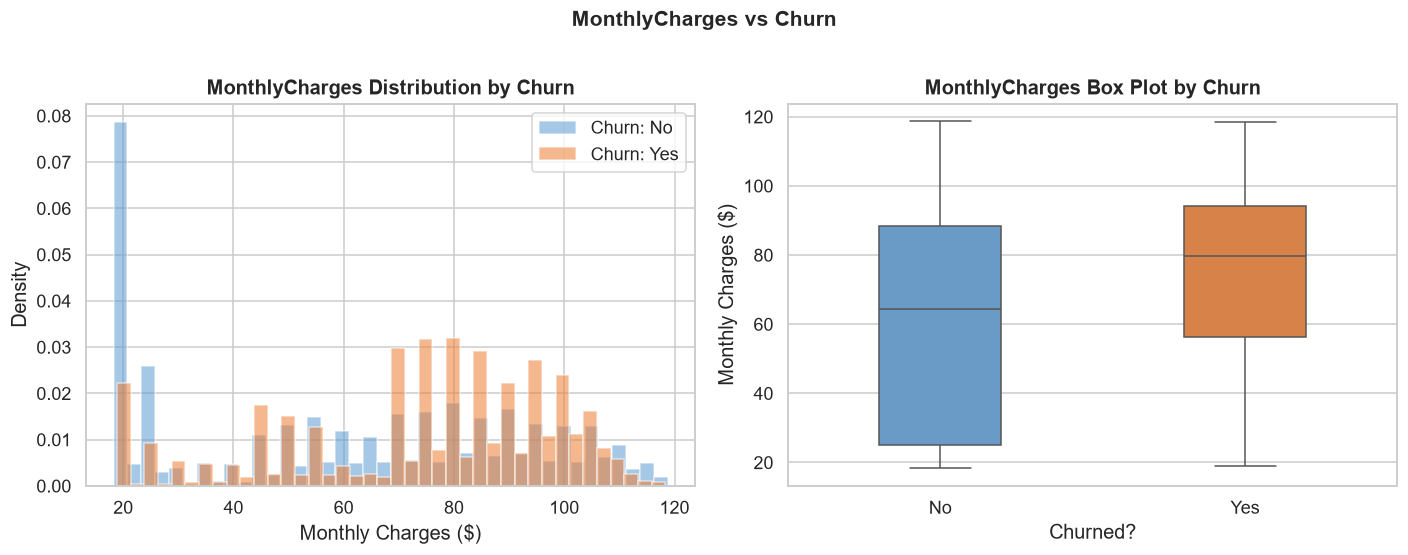

Saved: images/02_06_monthly_charges_vs_churn.png


In [11]:
print("=== MonthlyCharges statistics by Churn ===")
print(df.groupby("Churn")["MonthlyCharges"].describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: overlapping histograms
for label, grp in df.groupby("Churn"):
    axes[0].hist(
        grp["MonthlyCharges"],
        bins=40,
        alpha=0.55,
        label=f"Churn: {label}",
        color="#ed7d31" if label == "Yes" else "#5b9bd5",
        edgecolor="white",
        density=True,
    )
axes[0].set_title("MonthlyCharges Distribution by Churn", fontweight="bold")
axes[0].set_xlabel("Monthly Charges ($)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Right: box plot
churn_order = ["No", "Yes"]
plot_df = df.copy()
sns.boxplot(
    data=plot_df,
    x="Churn",
    y="MonthlyCharges",
    order=churn_order,
    palette={"No": "#5b9bd5", "Yes": "#ed7d31"},
    ax=axes[1],
    width=0.4,
)
axes[1].set_title("MonthlyCharges Box Plot by Churn", fontweight="bold")
axes[1].set_xlabel("Churned?")
axes[1].set_ylabel("Monthly Charges ($)")

fig.suptitle("MonthlyCharges vs Churn", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "02_06_monthly_charges_vs_churn.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_06_monthly_charges_vs_churn.png")

## 9. Correlation among numeric variables

We compute correlation only for the genuinely numeric variables: `tenure`, `MonthlyCharges`, `TotalCharges`, and `ChurnFlag`. 

**Important limits:** `TotalCharges` is highly correlated with both `tenure` and `MonthlyCharges` by definition (it accumulates them over time). `ChurnFlag` is a 0/1 binary; Pearson correlation with binary variables understates the true association. The heatmap shows direction and rough magnitude, not full explanatory power.

=== Pearson Correlation Matrix (numeric variables only) ===
                tenure  MonthlyCharges  TotalCharges  ChurnFlag
tenure           1.000           0.248         0.826     -0.352
MonthlyCharges   0.248           1.000         0.651      0.193
TotalCharges     0.826           0.651         1.000     -0.198
ChurnFlag       -0.352           0.193        -0.198      1.000

Note: TotalCharges ≈ tenure × MonthlyCharges, so its correlations are
mechanically inflated. ChurnFlag correlation is a point-biserial estimate.


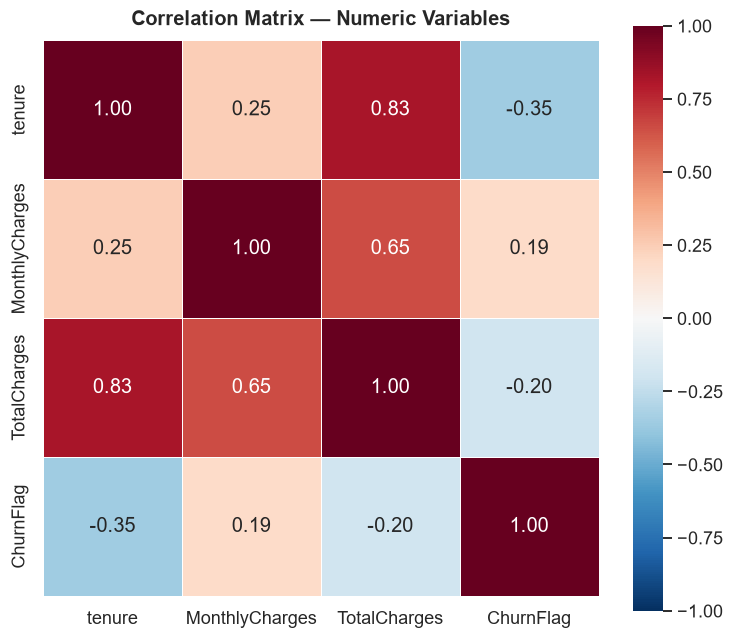

Saved: images/02_07_correlation_heatmap.png


In [12]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]
corr_matrix = df[numeric_cols].corr(method="pearson")

print("=== Pearson Correlation Matrix (numeric variables only) ===")
print(corr_matrix.round(3).to_string())
print()
print("Note: TotalCharges ≈ tenure × MonthlyCharges, so its correlations are")
print("mechanically inflated. ChurnFlag correlation is a point-biserial estimate.")

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    linewidths=0.5,
    square=True,
)
ax.set_title("Correlation Matrix — Numeric Variables", fontweight="bold", pad=10)
plt.tight_layout()
plt.savefig(images_dir / "02_07_correlation_heatmap.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_07_correlation_heatmap.png")

## 10. Churn rate heatmap: contract x internet service

Combining two strong predictors in a cross-tabulation reveals whether their effects are additive or concentrated in specific combinations. Month-to-month + Fiber Optic is the highest-risk combination by churn rate.

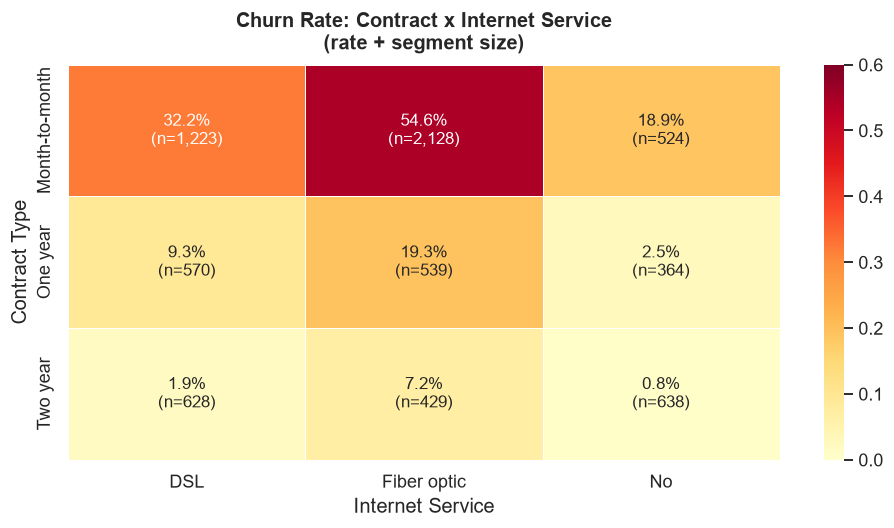

Saved: images/02_08_churn_heatmap_contract_internet.png


In [13]:
pivot_rate = df.pivot_table(
    values="ChurnFlag",
    index="Contract",
    columns="InternetService",
    aggfunc="mean",
)
pivot_count = df.pivot_table(
    values="ChurnFlag",
    index="Contract",
    columns="InternetService",
    aggfunc="count",
)

contract_order = ["Month-to-month", "One year", "Two year"]
pivot_rate = pivot_rate.reindex(contract_order)
pivot_count = pivot_count.reindex(contract_order)

# Annotation: rate + count on each cell
# Note: pandas 2.1+ uses .map() instead of the removed .applymap()
annot = pivot_rate.map(lambda v: f"{v:.1%}") + "\n(n=" + pivot_count.map(lambda v: f"{int(v):,}") + ")"

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    pivot_rate,
    annot=annot,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.6,
    linewidths=0.5,
    ax=ax,
    annot_kws={"size": 11},
)
ax.set_title("Churn Rate: Contract x Internet Service\n(rate + segment size)",
             fontweight="bold", pad=10)
ax.set_xlabel("Internet Service")
ax.set_ylabel("Contract Type")
plt.tight_layout()
plt.savefig(images_dir / "02_08_churn_heatmap_contract_internet.png", bbox_inches="tight")
plt.show()
print("Saved: images/02_08_churn_heatmap_contract_internet.png")

## 11. Summary of EDA findings

The cell below prints a structured text summary to give a quick overview before moving to deeper analysis in notebooks 03 and 04.

In [14]:
overall_rate = df["ChurnFlag"].mean()

mtm_rate = df[df["Contract"] == "Month-to-month"]["ChurnFlag"].mean()
twoyear_rate = df[df["Contract"] == "Two year"]["ChurnFlag"].mean()

early_rate = df[df["TenureBucket"] == "0–12 mo"]["ChurnFlag"].mean()
late_rate = df[df["TenureBucket"] == "61–72 mo"]["ChurnFlag"].mean()

echeck_rate = df[df["PaymentMethod"] == "Electronic check"]["ChurnFlag"].mean()
auto_rate = df[df["PaymentMethod"].isin(["Bank transfer (automatic)", "Credit card (automatic)"])]["ChurnFlag"].mean()

fiber_rate = df[df["InternetService"] == "Fiber optic"]["ChurnFlag"].mean()
dsl_rate = df[df["InternetService"] == "DSL"]["ChurnFlag"].mean()

senior_rate = df[df["SeniorCitizen"] == 1]["ChurnFlag"].mean()
nonsenior_rate = df[df["SeniorCitizen"] == 0]["ChurnFlag"].mean()

highest_risk = df[
    (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic")
]

print("============================================================")
print("  EDA KEY FINDINGS — Telco Customer Churn")
print("============================================================")
print(f"  Overall churn rate:          {overall_rate:.1%}")
print()
print("  Contract type")
print(f"    Month-to-month:            {mtm_rate:.1%}")
print(f"    Two year:                  {twoyear_rate:.1%}")
print()
print("  Tenure")
print(f"    First 12 months:           {early_rate:.1%}")
print(f"    61–72 months:              {late_rate:.1%}")
print()
print("  Payment method")
print(f"    Electronic check:          {echeck_rate:.1%}")
print(f"    Automatic methods (avg):   {auto_rate:.1%}")
print()
print("  Internet service")
print(f"    Fiber optic:               {fiber_rate:.1%}")
print(f"    DSL:                       {dsl_rate:.1%}")
print()
print("  Senior citizen")
print(f"    Senior (1):                {senior_rate:.1%}")
print(f"    Non-senior (0):            {nonsenior_rate:.1%}")
print()
print("  Highest-risk combination (Month-to-month + Fiber optic)")
print(f"    n = {len(highest_risk):,}  |  churn rate = {highest_risk['ChurnFlag'].mean():.1%}")
print("============================================================")
print()
print("Reminder: these are associations, not causal relationships.")
print("Segment sizes must be considered alongside rates.")

  EDA KEY FINDINGS — Telco Customer Churn
  Overall churn rate:          26.5%

  Contract type
    Month-to-month:            42.7%
    Two year:                  2.8%

  Tenure
    First 12 months:           47.4%
    61–72 months:              6.6%

  Payment method
    Electronic check:          45.3%
    Automatic methods (avg):   16.0%

  Internet service
    Fiber optic:               41.9%
    DSL:                       19.0%

  Senior citizen
    Senior (1):                41.7%
    Non-senior (0):            23.6%

  Highest-risk combination (Month-to-month + Fiber optic)
    n = 2,128  |  churn rate = 54.6%

Reminder: these are associations, not causal relationships.
Segment sizes must be considered alongside rates.
